# Neural Networks from Scratch with NumPy

Deep learning libraries hide the details, but understanding the mechanics makes you a better
practitioner. This notebook builds a small multilayer perceptron (MLP) using only NumPy:

- forward pass,
- binary cross-entropy loss,
- backpropagation,
- gradient descent,
- decision-boundary visualisation.

We then compare it with scikit-learn's `MLPClassifier`.

## Learning objectives

1. Explain the role of weights, biases, and activation functions.
2. Implement a forward pass for a two-layer network.
3. Derive and implement the backward pass for binary classification.
4. Train with gradient descent and diagnose the loss curve.
5. Compare a from-scratch model with a library implementation.

## 1. Concepts

### Perceptron to MLP

A single perceptron computes $y = \sigma(w^T x + b)$. Stacking layers lets the network learn
non-linear functions.

For a two-layer network:

$$
z_1 = XW_1 + b_1, \quad a_1 = \text{ReLU}(z_1)
$$
$$
z_2 = a_1W_2 + b_2, \quad \hat{y} = \sigma(z_2)
$$

### Loss

For binary classification we use binary cross-entropy:

$$
L = -\frac{1}{n}\sum_{i=1}^{n}\left[y_i\log(\hat{y}_i) + (1-y_i)\log(1-\hat{y}_i)\right]
$$

### Backpropagation

The chain rule gives:

$$
\frac{\partial L}{\partial z_2} = \hat{y} - y
$$
$$
\frac{\partial L}{\partial W_2} = a_1^T \frac{\partial L}{\partial z_2}, \quad
\frac{\partial L}{\partial b_2} = \sum \frac{\partial L}{\partial z_2}
$$
$$
\frac{\partial L}{\partial a_1} = \frac{\partial L}{\partial z_2} W_2^T, \quad
\frac{\partial L}{\partial z_1} = \frac{\partial L}{\partial a_1} \odot \mathbb{1}[z_1 > 0]
$$

### Training knobs

- **Learning rate**: too high diverges, too low is slow.
- **Epochs**: too few underfits, too many overfits.
- **Hidden width**: more units increase capacity.
- **Regularisation**: weight decay, dropout, early stopping.
- **Initialisation**: zero initialisation breaks symmetry; use random or He/Xavier initialisation.

## 2. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
sns.set_theme(style="whitegrid")

## 3. Data: two moons

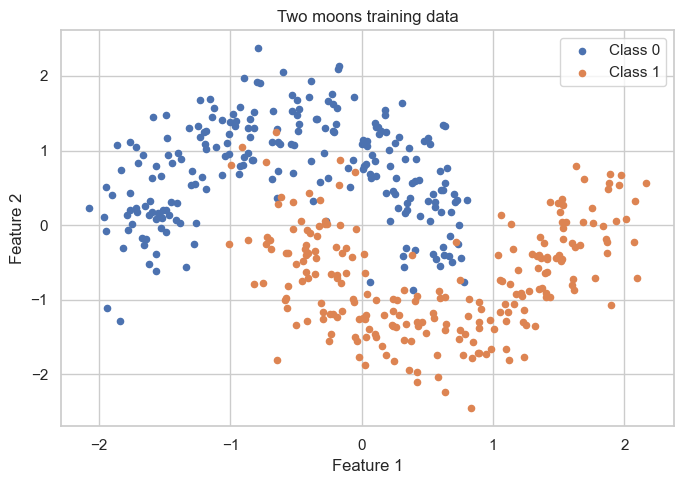

In [2]:
X, y = make_moons(n_samples=600, noise=0.20, random_state=RANDOM_STATE)
y = y.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y.ravel()
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

plt.figure(figsize=(7, 5))
plt.scatter(X_train[y_train.ravel() == 0, 0], X_train[y_train.ravel() == 0, 1], s=20, label="Class 0")
plt.scatter(X_train[y_train.ravel() == 1, 0], X_train[y_train.ravel() == 1, 1], s=20, label="Class 1")
plt.title("Two moons training data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Implement the network

The network has one hidden layer with 16 ReLU units and one sigmoid output. We use full-batch
gradient descent to keep the code readable.

In [3]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def relu(z):
    return np.maximum(0.0, z)

def binary_cross_entropy(y_true, y_pred):
    epsilon = 1e-9
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

input_dim = X_train.shape[1]
hidden_dim = 16

W1 = rng.normal(0, np.sqrt(2 / input_dim), size=(input_dim, hidden_dim))
b1 = np.zeros(hidden_dim)
W2 = rng.normal(0, np.sqrt(2 / hidden_dim), size=(hidden_dim, 1))
b2 = np.zeros(1)

learning_rate = 0.1
epochs = 3000
loss_history = []

for epoch in range(epochs):
    # Forward pass
    z1 = X_train @ W1 + b1
    a1 = relu(z1)
    z2 = a1 @ W2 + b2
    y_hat = sigmoid(z2)

    # Loss
    loss = binary_cross_entropy(y_train, y_hat)
    loss_history.append(loss)

    # Backward pass
    n = X_train.shape[0]
    dz2 = (y_hat - y_train) / n
    dW2 = a1.T @ dz2
    db2 = np.sum(dz2, axis=0)
    da1 = dz2 @ W2.T
    dz1 = da1 * (z1 > 0)
    dW1 = X_train.T @ dz1
    db1 = np.sum(dz1, axis=0)

    # Gradient descent update
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    if (epoch + 1) % 500 == 0:
        print(f"Epoch {epoch + 1:4d} | loss = {loss:.4f}")

def predict_proba(X):
    return sigmoid(relu(X @ W1 + b1) @ W2 + b2)

train_pred = (predict_proba(X_train) >= 0.5).astype(int)
test_pred = (predict_proba(X_test) >= 0.5).astype(int)
print("Train accuracy:", round(accuracy_score(y_train, train_pred), 4))
print("Test accuracy:", round(accuracy_score(y_test, test_pred), 4))

Epoch  500 | loss = 0.2125
Epoch 1000 | loss = 0.1516
Epoch 1500 | loss = 0.1286
Epoch 2000 | loss = 0.1190


Epoch 2500 | loss = 0.1141
Epoch 3000 | loss = 0.1115
Train accuracy: 0.9622
Test accuracy: 0.9667


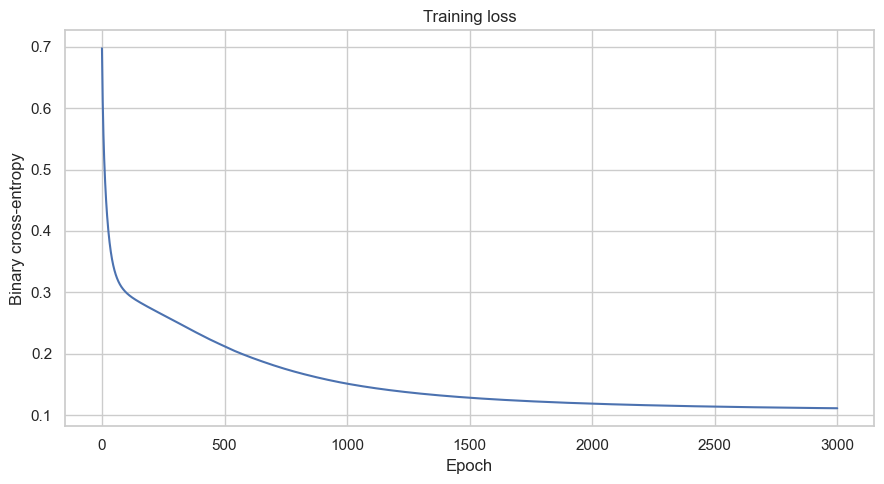

In [4]:
plt.figure(figsize=(9, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.title("Training loss")
plt.tight_layout()
plt.show()

## 5. Visualise the learned boundary

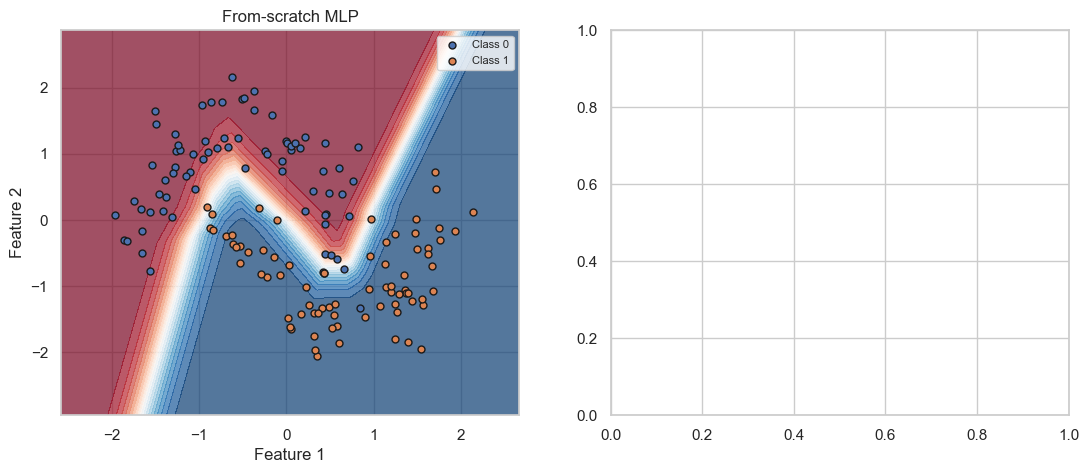

In [5]:
def plot_boundary(ax, probability_fn, title):
    x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
    y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    probabilities = probability_fn(grid).reshape(xx.shape)
    ax.contourf(xx, yy, probabilities, levels=20, cmap="RdBu", alpha=0.7)
    ax.scatter(X_test[y_test.ravel() == 0, 0], X_test[y_test.ravel() == 0, 1],
               edgecolor="k", s=25, label="Class 0")
    ax.scatter(X_test[y_test.ravel() == 1, 0], X_test[y_test.ravel() == 1, 1],
               edgecolor="k", s=25, label="Class 1")
    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.legend(loc="upper right", fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_boundary(axes[0], predict_proba, "From-scratch MLP")

## 6. Compare with scikit-learn

`MLPClassifier` uses the same basic building blocks but adds mini-batch training, adaptive optimisers,
and many practical safeguards.

In [6]:
sklearn_mlp = MLPClassifier(
    hidden_layer_sizes=(16,),
    activation="relu",
    solver="adam",
    max_iter=3000,
    random_state=RANDOM_STATE,
)
sklearn_mlp.fit(X_train, y_train.ravel())

print("sklearn train accuracy:", round(sklearn_mlp.score(X_train, y_train.ravel()), 4))
print("sklearn test accuracy:", round(sklearn_mlp.score(X_test, y_test.ravel()), 4))
plot_boundary(axes[1], lambda grid: sklearn_mlp.predict_proba(grid)[:, 1], "scikit-learn MLP")
plt.tight_layout()
plt.show()

sklearn train accuracy: 0.9556
sklearn test accuracy: 0.9533


<Figure size 640x480 with 0 Axes>

## 7. Experiments to try

- Change `hidden_dim` to 2, 8, 64 and observe the boundary.
- Change `learning_rate` to 0.001 and 1.0. What happens to the loss?
- Add L2 regularisation by adding `0.01 * W1` and `0.01 * W2` to the gradients.
- Use mini-batches instead of full-batch updates.
- Add a second hidden layer.
- Replace ReLU with tanh or sigmoid and compare convergence.

## Key takeaways

- A neural network is a composition of linear transformations and non-linear activations.
- Backpropagation is the chain rule applied efficiently.
- Initialisation, learning rate, and architecture strongly affect training.
- Loss curves are a first diagnostic for underfitting and divergence.
- Libraries add optimisers, regularisation, GPU support, and numerical safeguards.

## Exercises

1. Implement mini-batch gradient descent with batch size 32.
2. Add weight decay and compare the decision boundary.
3. Implement early stopping using a validation split.
4. Derive the gradient for a mean-squared-error loss with a linear output.
5. Explain why zero-initialising all weights prevents learning.
6. When would you choose a neural network over a random forest for tabular data?